# Extra Figure 1 — the Figure 3 sweep for the CCZ at $L=12$ and $L=120$

Five methods on the same problem: Three Newton rules (Armijo on infidelity), GEOPE (Armijo on geodesic distance), and L-BFGS (Armijo + Strong Wolfe on infidelity). Run both initial spreads.

In [1]:
from common import *


# Get data

In [2]:
N_RUNS = 100
#: (L, title of the iteration panel, title of the wall-clock panel)
CASES = [
    (12, r"(a) CCZ, $L=12$", r"(b) $L=12$, wall clock"),
    (120, r"(c) CCZ, $L=120$", r"(d) $L=120$, wall clock"),
]
# Hyper parameters come from figE_hyperparameter_search.ipynb
METHODS = {
    "GEOPE": Armijo(),
    "LBFGS": LBFGS(memory=100),
    "NewtonTRM": NewtonTRM(delta=1e-3),
    "NewtonRFO": NewtonRFO(kappa=10**6),
    "NewtonSaddleFree": NewtonSaddleFree(),
}


def fig1_config(steps, method, config, spread):
    """Everything that changes this block's numbers.

    The spread is in the *tag* as well as in the config, so a block is
    identifiable on disk without opening its sidecar. It is stored as a float:
    ``json.dumps`` writes ``1`` and ``1.0`` differently, so an int would key a
    second block under the same tag.
    """
    cfg = {
        "tag": f"fig1_CCZ_L{steps}_{spread_slug(spread)}_{method}",
        "kind": "fig1-ccz-iterations-walltime",
        "gate": "CCZ",
        "steps": steps,
        "method": method,
        "config": repr(config),
        "spread": float(spread),
        "n_qubits": 3,
        "max_steps": MAX_STEPS,
        "precision": PRECISION,
    }
    if method == "GEOPE":
        cfg["geope_max_step"] = GEOPE_MAX_STEP
    return cfg


def fig1_sweep(n_runs=None, force=False, spread=SPREAD):
    """Every ``(L, method)`` block at one spread, keyed ``(steps, method)``."""
    n_runs = N_RUNS if n_runs is None else n_runs
    blocks = {}
    for steps, _iter_title, _time_title in CASES:
        for method, config in METHODS.items():

            def build(steps=steps, method=method, config=config):
                params = make_parameters(3, steps, "CCZ", spread=spread)
                optimiser = (
                    Geope(params, history=History())
                    if method == "GEOPE"
                    else Grape(params, precision=PRECISION, history=History())
                )
                return params, optimiser, config

            blocks[(steps, method)] = run_block(
                fig1_config(steps, method, config, spread),
                build,
                n_runs,
                spread=spread,
                force=force,
            )
    return blocks


fig1_blocks = fig1_sweep(spread=0.01)
fig1_blocks = fig1_sweep(spread=1.0)

  fig1_CCZ_L12_spread0p01pi_GEOPE          100/100 converged  median   0.06s   cached (100 stored)


  fig1_CCZ_L12_spread0p01pi_LBFGS          100/100 converged  median   0.09s   cached (100 stored)


  fig1_CCZ_L12_spread0p01pi_NewtonTRM      60/100 converged  median   0.08s   cached (100 stored)


  fig1_CCZ_L12_spread0p01pi_NewtonRFO      99/100 converged  median   0.13s   cached (100 stored)


  fig1_CCZ_L12_spread0p01pi_NewtonSaddleFree 100/100 converged  median   0.06s   cached (100 stored)


  fig1_CCZ_L120_spread0p01pi_GEOPE         100/100 converged  median   0.15s   cached (100 stored)


... (10 outputs left out)

  fig1_CCZ_L120_spread1pi_LBFGS            100/100 converged  median   0.06s   cached (100 stored)


  fig1_CCZ_L120_spread1pi_NewtonTRM        100/100 converged  median   2.17s   cached (100 stored)


  fig1_CCZ_L120_spread1pi_NewtonRFO        100/100 converged  median   7.24s   cached (100 stored)


  fig1_CCZ_L120_spread1pi_NewtonSaddleFree 100/100 converged  median   2.38s   cached (100 stored)


# Combined figure: iteration versus wallclock time

  fig1_CCZ_L12_spread0p01pi_GEOPE          100/100 converged  median   0.06s   cached (100 stored)


  fig1_CCZ_L12_spread0p01pi_LBFGS          100/100 converged  median   0.09s   cached (100 stored)


  fig1_CCZ_L12_spread0p01pi_NewtonTRM      60/100 converged  median   0.08s   cached (100 stored)


  fig1_CCZ_L12_spread0p01pi_NewtonRFO      99/100 converged  median   0.13s   cached (100 stored)


  fig1_CCZ_L12_spread0p01pi_NewtonSaddleFree 100/100 converged  median   0.06s   cached (100 stored)


  fig1_CCZ_L120_spread0p01pi_GEOPE         100/100 converged  median   0.15s   cached (100 stored)


... (12 outputs left out)

  fig1_CCZ_L120_spread1pi_NewtonRFO        100/100 converged  median   7.24s   cached (100 stored)


  fig1_CCZ_L120_spread1pi_NewtonSaddleFree 100/100 converged  median   2.38s   cached (100 stored)


<>:2: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:2: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:2: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:2: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
/var/folders/q5/0cxswx_129vgr9_vny6x9q2r0000gn/T/ipykernel_94434/404352516.py:2: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  SPREAD_ROWS = [(0.01, "ab", "\pi/100"), (1.0, "cd", "\pi")]
/var/folders/q5/0cxswx_129vgr9_vny6x9q2r0000gn/T/ipykernel_94434/404352516.py:2: SyntaxWarning: "\

figures/extra_fig1_ccz_spread0p01pi_spread1pi.pdf


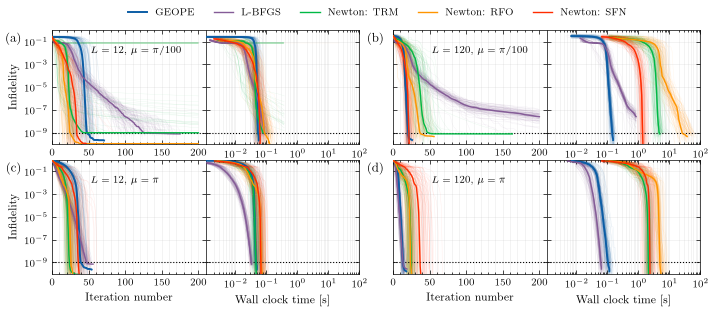

In [3]:
#: One row per initial spread
SPREAD_ROWS = [(0.01, "ab", "\pi/100"), (1.0, "cd", "\pi")]

fig1_by_spread = {
    spread: fig1_sweep(spread=spread) for spread, _letters, _pi_label in SPREAD_ROWS
}

fig = plt.figure(figsize=(TWO_COLUMN, 2.9))
gs = fig.add_gridspec(2, 5, width_ratios=[1, 1, 0.22, 1, 1], wspace=0.0, hspace=0.14)
first = fig.add_subplot(gs[0, 0])
axes = {
    (row, col): (
        first if (row, col) == (0, 0) else fig.add_subplot(gs[row, col], sharey=first)
    )
    for row in (0, 1)
    for col in (0, 1, 3, 4)
}

for row, (spread, letters, pi_label) in enumerate(SPREAD_ROWS):
    sweep = fig1_by_spread[spread]
    pairs = ((axes[row, 0], axes[row, 1]), (axes[row, 3], axes[row, 4]))
    for col, (
        (steps, _iter_title, _time_title),
        (ax_iter, ax_time),
        letter,
    ) in enumerate(zip(CASES, pairs, letters)):
        blocks = {m: sweep[(steps, m)] for m in METHODS}
        draw_iterations(ax_iter, blocks, METHODS)
        draw_walltime(ax_time, blocks, METHODS)
        finish(ax_iter, "")
        finish(ax_time, "")
        # ax_iter.xaxis.set_major_locator(MaxNLocator(4, prune="upper"))
        ax_iter.text(
            -0.06 + (col - 1) * 0.14,
            0.98,
            rf"({letter})",
            transform=ax_iter.transAxes,
            ha="right",
            va="top",
            fontsize=PANEL_LABEL_SIZE,
            zorder=5,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.2),
        )

        ax_iter.text(
            0.25,
            0.8,
            rf"$L={steps}$, $\mu={pi_label}$",
            transform=ax_iter.transAxes,
            fontsize=ANNOTATION_SIZE,
            zorder=5,
        )
        # ax_iter.set_title(rf"$L={steps}$, spread = {spread:1.2f}$\pi$", x=1.0)
        ax_iter.set_xlim(0, 210)
        ax_time.set_xlim(1.1e-3, 1e2)


# One y-axis per merged panel: only the far-left sub-plot of a row keeps its
# labels.
for (row, col), ax in axes.items():
    if col != 0:
        ax.tick_params(labelleft=False)
    else:
        ax.set_ylabel(r"Infidelity")
    if row == 0:
        ax.set_xlabel("")
        # ax.set_xticks([])

# One legend under all eight sub-plots
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.53, 1.0),
)
fig.subplots_adjust(left=0.072, right=0.985, top=0.985, bottom=0.145, wspace=0.0)
print(
    save_figure(
        fig,
        "extra_fig1_ccz_"
        + "_".join(spread_slug(s) for s, _letters, _pi_label in SPREAD_ROWS),
    )
)
plt.show()